# 17 · Comparing all the models

Notebooks 13 to 16 each trained one family of models and saved a results table. This notebook **trains nothing**: it reads those four tables and puts the models side by side.

| notebook | file | models |
|---|---|---|
| 13 | `linear_baselines.csv` | linear (logistic) model, no links |
| 14 | `graphsage_results.csv` | GraphSAGE, no-links MLP, GraphSAGE without same-patient links |
| 15 | `gat_results.csv` | GAT, no-links MLP, GAT without same-patient links |
| 16 | `gcn_results.csv` | GCN, edge-weighted GCN, no-links MLP, GCN without same-patient links |

**How the comparison is made fair**

- Every notebook used the **same patient-grouped splits for the same split seed**, so two models are compared **paired by seed** (split luck cancels). Only seeds that *every* model in a table ran are used, so a model that ran more seeds is not flattered.
- A pairing is made only if both models were scored on **the same stays**. Runs restricted to a subset (for example stays with a CLMBR vector) have different splits and are skipped, never silently mixed.
- The three "no links" MLPs are the same idea trained through each architecture's code. They should agree; **how far apart they are is a noise floor** for judging differences between architectures.
- Everything is on the **honest network with honest diagnoses** unless a table says otherwise.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ehrgraph.gnn import model_comparison as CM
from ehrgraph.gnn.linear_regressor import YEAR_BANDS
from ehrgraph.project import setup
from ehrgraph.viz import network_figures as nf

p = setup()
nf.apply_style()

TASKS = {"guo_los": "long stay", "new_hypertension": "new high blood pressure"}
LINEAR_MODEL = "logistic"      # the model notebook 13 used (its MODEL setting); only the year-alone reference needs this
COLOR = {"Linear": "#444444", "GraphSAGE": "#2b7bba", "GAT": "#7b4fa3", "GCN": "#2a9d8f"}

data folder: /home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/data/omop
results go to: /home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/results/aggregate


## Load the four results tables

The inventory shows, per question, how many split seeds each model ran in the honest scenario and how many stays it was scored on. **If `stays` differs between models, they were not scored on the same stays** and the paired comparisons below will be blank for them.

In [2]:
D, missing = CM.load_all(p.results)
if missing:
    print("NOT FOUND (run these notebooks first):", missing)

inv = []
for q in TASKS.values():
    for l in CM.CORE + sorted(set(D.label) - set(CM.CORE)):
        g = CM.get(D, q, l, *CM.HONEST) if l in set(D.label) else []
        if len(g):
            inv.append({"question": q, "model": l, "seeds": len(g), "first seeds": sorted(g.index)[:3] + ["..."] if len(g) > 3 else sorted(g.index),
                        "stays": sorted(g["n_used"].unique())})
display(pd.DataFrame(inv).set_index(["question", "model"]))
for q in TASKS.values():
    stays = {tuple(r["stays"]) for r in inv if r["question"] == q}
    print(f"{q}: " + ("all models scored on the same stays" if len(stays) == 1 else f"DIFFERENT stays across models: {stays}"))

seeds  \
question                model                                      
long stay               Linear                                10   
                        MLP via GraphSAGE                      5   
                        MLP via GAT                            5   
                        MLP via GCN                            5   
                        GraphSAGE                              5   
                        GAT                                    5   
                        GCN                                    5   
                        GAT (no same-patient links)            5   
                        GCN (no same-patient links)            5   
                        GCN (weighted)                         5   
                        GraphSAGE (no same-patient links)      5   
new high blood pressure Linear                                10   
                        MLP via GraphSAGE                      5   
                        MLP via GAT                            5   
                        MLP via GCN                            5   
                        GraphSAGE                              5   
                        GAT                                    5   
                        GCN                                    5   
                        GAT (no same-patient links)            5   
                        GCN (no same-patient links)            5   
                        GCN (weighted)                         5   
                        GraphSAGE (no same-patient links)      5   

                                                              first seeds  \
question                model                                               
long stay               Linear                             [0, 1, 2, ...]   
                        MLP via GraphSAGE                  [0, 1, 2, ...]   
                        MLP via GAT                        [0, 1, 2, ...]   
                        MLP via GCN                        [0, 1, 2, ...]   
                        GraphSAGE                          [0, 1, 2, ...]   
                        GAT                                [0, 1, 2, ...]   
                        GCN                                [0, 1, 2, ...]   
                        GAT (no same-patient links)        [0, 1, 2, ...]   
                        GCN (no same-patient links)        [0, 1, 2, ...]   
                        GCN (weighted)                     [0, 1, 2, ...]   
                        GraphSAGE (no same-patient links)  [0, 1, 2, ...]   
new high blood pressure Linear                             [0, 1, 2, ...]   
                        MLP via GraphSAGE                  [0, 1, 2, ...]   
                        MLP via GAT                        [0, 1, 2, ...]   
                        MLP via GCN                        [0, 1, 2, ...]   
                        GraphSAGE                          [0, 1, 2, ...]   
                        GAT                                [0, 1, 2, ...]   
                        GCN                                [0, 1, 2, ...]   
                        GAT (no same-patient links)        [0, 1, 2, ...]   
                        GCN (no same-patient links)        [0, 1, 2, ...]   
                        GCN (weighted)                     [0, 1, 2, ...]   
                        GraphSAGE (no same-patient links)  [0, 1, 2, ...]   

                                                              stays  
question                model                                        
long stay               Linear                                [nan]  
                        MLP via GraphSAGE                  [6998.0]  
                        MLP via GAT                        [6998.0]  
                        MLP via GCN                        [6998.0]  
                        GraphSAGE                          [6998.0]  
                        GAT                                [6998.0]  
                 

long stay: DIFFERENT stays across models: {(np.float64(6998.0),), (np.float64(nan),)}
new high blood pressure: DIFFERENT stays across models: {(np.float64(3511.0),), (np.float64(nan),)}


## Reference: the calendar year alone

The prediction year as the only feature, on the same splits (the same calculation as notebook 13). The blood-pressure rate falls about fourfold across years, so a model near this score has learned little beyond the calendar. Set `LINEAR_MODEL` above to match what notebook 13 used.

In [3]:
YEAR = {}
try:
    for t, q in TASKS.items():
        lab = p.labels(t)
        lab = lab[lab["patient_id"].isin(set(p.diagnoses))].reset_index(drop=True)      # same filter as the graph builder
        seeds = CM.common_seeds(D, q, [l for l in CM.CORE if len(CM.get(D, q, l, *CM.HONEST))])
        r = CM.year_alone(lab["value"].astype(int).to_numpy(), pd.factorize(lab["patient_id"])[0],
                          pd.to_datetime(lab["prediction_time"]).dt.year.to_numpy(), seeds, LINEAR_MODEL)
        YEAR[q] = r
        print(f"{q}: year alone, test AUROC {r.test_auc.mean():.3f} ± {r.test_auc.std():.3f} over {len(r)} splits")
except Exception as e:                                       # the comparison does not depend on this reference
    print("year-alone reference skipped:", type(e).__name__, e)

long stay: year alone, test AUROC 0.496 ± 0.022 over 5 splits
new high blood pressure: year alone, test AUROC 0.633 ± 0.030 over 5 splits


## The leaderboard

Honest network, honest diagnoses. For each model: the mean and spread of test AUROC over the shared seeds, its **mean rank** among the seven core models (1 = best) and the **share of splits it won**, then two paired differences (mean ± spread across splits):

- `vs_linear`: against the linear model.
- `vs_own_mlp`: against the no-links MLP of **its own architecture**. This is what the network adds, with the architecture held fixed.

`_frac` is the share of splits where the model came out higher. A difference smaller than its spread is not a finding. The "no same-patient links" and "weighted" variants are listed for reference and are not ranked.

In [4]:
LB = {q: CM.leaderboard(D, q) for q in TASKS.values()}
for q, lb in LB.items():
    print(f"{q} - test AUROC on the honest network with honest diagnoses")
    display(lb.drop(columns=["kind"]).round(3))

long stay - test AUROC on the honest network with honest diagnoses


,n_seeds,mean,sd,test_ap,mean_rank,share_of_splits_won,vs_linear,vs_linear_frac,vs_own_mlp,vs_own_mlp_frac
model,,,,,,,,,,
Linear,5,0.747,0.020,0.483,6.4,0.0,,NaN,,NaN
MLP via GraphSAGE,5,0.776,0.014,0.552,2.2,0.4,,NaN,,NaN
MLP via GAT,5,0.777,0.015,0.545,2.6,0.4,,NaN,,NaN
MLP via GCN,5,0.771,0.018,0.537,3.2,0.2,,NaN,,NaN
GraphSAGE,5,0.768,0.023,0.543,4.0,0.0,,NaN,-0.008 ± 0.016,0.4
GAT,5,0.765,0.010,0.519,4.2,0.0,,NaN,-0.013 ± 0.012,0.2
GCN,5,0.756,0.016,0.509,5.4,0.0,,NaN,-0.015 ± 0.014,0.2
GraphSAGE (no same-patient links),5,0.764,0.018,0.535,NaN,NaN,,NaN,-0.012 ± 0.011,0.2
GAT (no same-patient links),5,0.772,0.009,0.530,NaN,NaN,,NaN,-0.005 ± 0.014,0.2


new high blood pressure - test AUROC on the honest network with honest diagnoses


,n_seeds,mean,sd,test_ap,mean_rank,share_of_splits_won,vs_linear,vs_linear_frac,vs_own_mlp,vs_own_mlp_frac
model,,,,,,,,,,
Linear,5,0.594,0.025,0.148,6.6,0.0,,NaN,,NaN
MLP via GraphSAGE,5,0.673,0.034,0.255,3.6,0.0,,NaN,,NaN
MLP via GAT,5,0.691,0.037,0.273,1.6,0.4,,NaN,,NaN
MLP via GCN,5,0.649,0.068,0.234,5.2,0.0,,NaN,,NaN
GraphSAGE,5,0.668,0.055,0.250,3.6,0.2,,NaN,-0.005 ± 0.033,0.6
GAT,5,0.672,0.030,0.278,3.1,0.2,,NaN,-0.018 ± 0.016,0.2
GCN,5,0.655,0.045,0.251,4.3,0.2,,NaN,+0.006 ± 0.056,0.6
GraphSAGE (no same-patient links),5,0.659,0.029,0.241,NaN,NaN,,NaN,-0.015 ± 0.010,0.0
GAT (no same-patient links),5,0.670,0.030,0.265,NaN,NaN,,NaN,-0.021 ± 0.016,0.0


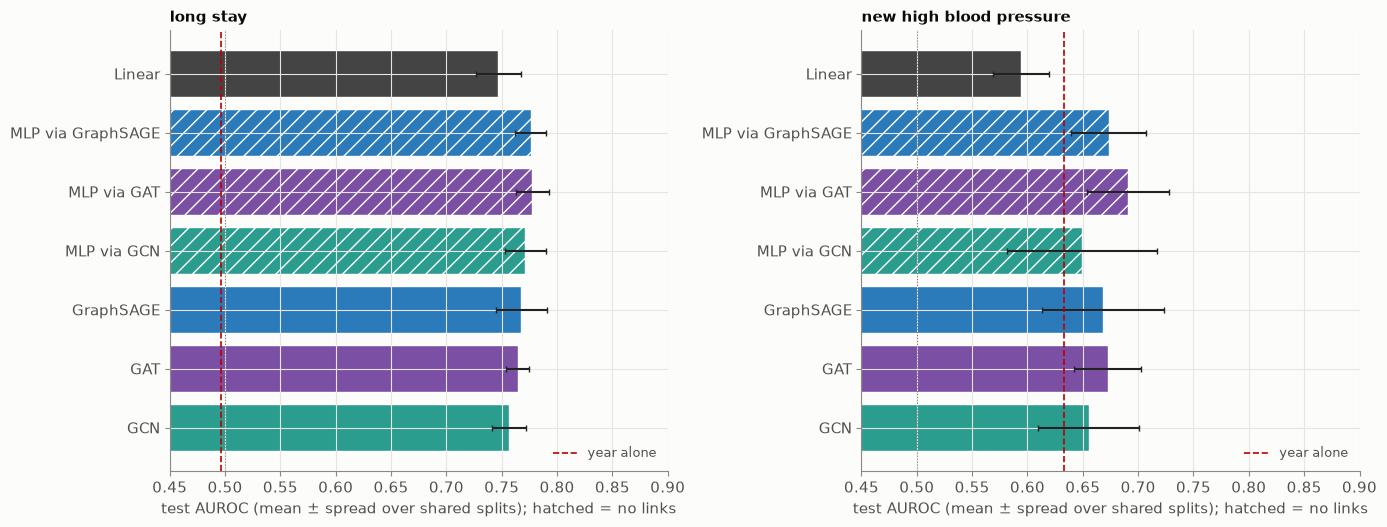

In [5]:
fig, axes = plt.subplots(1, len(TASKS), figsize=(14, 5.4))
for ax, q in zip(np.atleast_1d(axes), TASKS.values()):
    lb = LB[q].loc[[m for m in LB[q].index if m in CM.CORE]].iloc[::-1]
    colors = [COLOR[CM._arch_of(D, m)] for m in lb.index]
    hatches = ["//" if m.startswith("MLP") else "" for m in lb.index]
    bars = ax.barh(lb.index, lb["mean"], xerr=lb["sd"], color=colors, ecolor="#222", capsize=2)
    for b, h in zip(bars, hatches):
        b.set_hatch(h); b.set_edgecolor("white")
    if q in YEAR:
        ax.axvline(YEAR[q].test_auc.mean(), color="#b00", lw=1.2, ls="--", label="year alone")
        ax.legend(loc="lower right", frameon=False)
    ax.axvline(0.5, color="grey", lw=0.8, ls=":")
    ax.set_xlim(0.45, max(0.9, float((lb["mean"] + lb["sd"]).max()) + 0.02)); ax.set_title(q)
    ax.set_xlabel("test AUROC (mean ± spread over shared splits); hatched = no links")
plt.tight_layout()
nf.save(fig, p.figures / "17_model_comparison.png")
plt.show()

## Does the network help, for each architecture?

Every row is A minus B, paired by split seed, in test AUROC. The first row of each block is the key one: **network minus the no-links MLP of the same architecture**. Read it against its spread. The others check that any gain is about the *real* network (versus a random one), whether it needs the same-patient links, and, for GCN, whether the edge weights add anything.

In [6]:
NE = {q: CM.network_effects(D, q) for q in TASKS.values()}
for q, df in NE.items():
    print(q)
    display(df.set_index(["architecture", "comparison"]).round(3))

long stay


mean_diff  \
architecture comparison                                                      
GraphSAGE    network adds (honest net):  network - MLP              -0.008   
             network adds (cheating net):  network - MLP            -0.017   
             cheating network vs honest                             -0.009   
             without same-patient links:  no-same - MLP             -0.012   
             same-patient links matter?  network - no-same           0.004   
GAT          network adds (honest net):  network - MLP              -0.013   
             network adds (cheating net):  network - MLP            -0.019   
             cheating network vs honest                             -0.006   
             without same-patient links:  no-same - MLP             -0.005   
             same-patient links matter?  network - no-same          -0.008   
GCN          network adds (honest net):  network - MLP              -0.015   
             network adds (cheating net):  network - MLP            -0.026   
             cheating network vs honest                             -0.011   
             without same-patient links:  no-same - MLP             -0.005   
             same-patient links matter?  network - no-same          -0.009   
             edge weights add (honest net):  weighted - unwe...      0.002   
             edge weights add (cheating net):  weighted - un...      0.012   

                                                                    sd  \
architecture comparison                                                  
GraphSAGE    network adds (honest net):  network - MLP           0.016   
             network adds (cheating net):  network - MLP         0.014   
             cheating network vs honest                          0.013   
             without same-patient links:  no-same - MLP          0.011   
             same-patient links matter?  network - no-same       0.007   
GAT          network adds (honest net):  network - MLP           0.012   
             network adds (cheating net):  network - MLP         0.011   
             cheating network vs honest                          0.010   
             without same-patient links:  no-same - MLP          0.014   
             same-patient links matter?  network - no-same       0.006   
GCN          network adds (honest net):  network - MLP           0.014   
             network adds (cheating net):  network - MLP         0.009   
             cheating network vs honest                          0.015   
             without same-patient links:  no-same - MLP          0.008   
             same-patient links matter?  network - no-same       0.011   
             edge weights add (honest net):  weighted - unwe...  0.007   
             edge weights add (cheating net):  weighted - un...  0.008   

                                                                 n_seeds  \
architecture comparison                                                    
GraphSAGE    network adds (honest net):  network - MLP                 5   
             network adds (cheating net):  network - MLP               5   
             cheating network vs honest                                5   
             without same-patient links:  no-same - MLP                5   
             same-patient links matter?  network - no-same             5   
GAT          network adds (honest net):  network - MLP                 5   
             network adds (cheating net):  network - MLP               5   
             cheating network vs honest                                5   
             without same-patient links:  no-same - MLP                5   
             same-patient links matter?  network - no-same             5   
GCN          network adds (honest net):  network - MLP                 5   
             network adds (cheating net):  network - MLP               5   
             cheating network vs honest                                5   
             without same-patient l

new high blood pressure


mean_diff  \
architecture comparison                                                      
GraphSAGE    network adds (honest net):  network - MLP              -0.005   
             network adds (cheating net):  network - MLP             0.008   
             cheating network vs honest                              0.013   
             without same-patient links:  no-same - MLP             -0.015   
             same-patient links matter?  network - no-same           0.009   
GAT          network adds (honest net):  network - MLP              -0.018   
             network adds (cheating net):  network - MLP             0.032   
             cheating network vs honest                              0.050   
             without same-patient links:  no-same - MLP             -0.021   
             same-patient links matter?  network - no-same           0.002   
GCN          network adds (honest net):  network - MLP               0.006   
             network adds (cheating net):  network - MLP             0.067   
             cheating network vs honest                              0.061   
             without same-patient links:  no-same - MLP             -0.013   
             same-patient links matter?  network - no-same           0.019   
             edge weights add (honest net):  weighted - unwe...      0.014   
             edge weights add (cheating net):  weighted - un...     -0.007   

                                                                    sd  \
architecture comparison                                                  
GraphSAGE    network adds (honest net):  network - MLP           0.033   
             network adds (cheating net):  network - MLP         0.040   
             cheating network vs honest                          0.029   
             without same-patient links:  no-same - MLP          0.010   
             same-patient links matter?  network - no-same       0.039   
GAT          network adds (honest net):  network - MLP           0.016   
             network adds (cheating net):  network - MLP         0.015   
             cheating network vs honest                          0.018   
             without same-patient links:  no-same - MLP          0.016   
             same-patient links matter?  network - no-same       0.006   
GCN          network adds (honest net):  network - MLP           0.056   
             network adds (cheating net):  network - MLP         0.050   
             cheating network vs honest                          0.015   
             without same-patient links:  no-same - MLP          0.056   
             same-patient links matter?  network - no-same       0.008   
             edge weights add (honest net):  weighted - unwe...  0.009   
             edge weights add (cheating net):  weighted - un...  0.015   

                                                                 n_seeds  \
architecture comparison                                                    
GraphSAGE    network adds (honest net):  network - MLP                 5   
             network adds (cheating net):  network - MLP               5   
             cheating network vs honest                                5   
             without same-patient links:  no-same - MLP                5   
             same-patient links matter?  network - no-same             5   
GAT          network adds (honest net):  network - MLP                 5   
             network adds (cheating net):  network - MLP               5   
             cheating network vs honest                                5   
             without same-patient links:  no-same - MLP                5   
             same-patient links matter?  network - no-same             5   
GCN          network adds (honest net):  network - MLP                 5   
             network adds (cheating net):  network - MLP               5   
             cheating network vs honest                                5   
             without same-patient l

## Does cheating show up, and in which models?

*Cheating diagnoses* use the whole record, including diagnoses made after the prediction time. *Cheating network* links stays by that same whole-record similarity. Each row is A minus B in test AUROC, paired by seed.

- **Cheating diagnoses vs honest** is feature leakage. It can show up in every model, with or without links.
- **Both cheat vs both honest** adds the cheating network on top.
- A model that does not use the links cannot show a leak that travels through them. The no-links MLPs are the reference for what feature leakage alone does.

In [7]:
CE = {q: CM.cheating_effects(D, q) for q in TASKS.values()}
for q, df in CE.items():
    print(q)
    display(df.set_index(["model", "comparison"]).round(3))

long stay


mean_diff     sd  \
model             comparison                                                    
MLP via GraphSAGE cheating diagnoses vs honest (honest net)     -0.018  0.022   
MLP via GAT       cheating diagnoses vs honest (honest net)     -0.010  0.029   
MLP via GCN       cheating diagnoses vs honest (honest net)     -0.011  0.016   
GraphSAGE         cheating diagnoses vs honest (honest net)     -0.017  0.029   
                  both cheat vs both honest                     -0.016  0.024   
GAT               cheating diagnoses vs honest (honest net)     -0.004  0.025   
                  both cheat vs both honest                     -0.010  0.019   
GCN               cheating diagnoses vs honest (honest net)     -0.004  0.016   
                  both cheat vs both honest                     -0.010  0.018   

                                                             n_seeds  \
model             comparison                                           
MLP via GraphSAGE cheating diagnoses vs honest (honest net)        5   
MLP via GAT       cheating diagnoses vs honest (honest net)        5   
MLP via GCN       cheating diagnoses vs honest (honest net)        5   
GraphSAGE         cheating diagnoses vs honest (honest net)        5   
                  both cheat vs both honest                        5   
GAT               cheating diagnoses vs honest (honest net)        5   
                  both cheat vs both honest                        5   
GCN               cheating diagnoses vs honest (honest net)        5   
                  both cheat vs both honest                        5   

                                                             fraction_a_higher  
model             comparison                                                    
MLP via GraphSAGE cheating diagnoses vs honest (honest net)                0.2  
MLP via GAT       cheating diagnoses vs honest (honest net)                0.4  
MLP via GCN       cheating diagnoses vs honest (honest net)                0.4  
GraphSAGE         cheating diagnoses vs honest (honest net)                0.2  
                  both cheat vs both honest                                0.2  
GAT               cheating diagnoses vs honest (honest net)                0.6  
                  both cheat vs both honest                                0.4  
GCN               cheating diagnoses vs honest (honest net)                0.4  
                  both cheat vs both honest                                0.4

new high blood pressure


mean_diff     sd  \
model             comparison                                                    
MLP via GraphSAGE cheating diagnoses vs honest (honest net)      0.222  0.036   
MLP via GAT       cheating diagnoses vs honest (honest net)      0.203  0.040   
MLP via GCN       cheating diagnoses vs honest (honest net)      0.252  0.066   
GraphSAGE         cheating diagnoses vs honest (honest net)      0.214  0.048   
                  both cheat vs both honest                      0.212  0.066   
GAT               cheating diagnoses vs honest (honest net)      0.122  0.033   
                  both cheat vs both honest                      0.164  0.047   
GCN               cheating diagnoses vs honest (honest net)      0.146  0.033   
                  both cheat vs both honest                      0.180  0.045   

                                                             n_seeds  \
model             comparison                                           
MLP via GraphSAGE cheating diagnoses vs honest (honest net)        5   
MLP via GAT       cheating diagnoses vs honest (honest net)        5   
MLP via GCN       cheating diagnoses vs honest (honest net)        5   
GraphSAGE         cheating diagnoses vs honest (honest net)        5   
                  both cheat vs both honest                        5   
GAT               cheating diagnoses vs honest (honest net)        5   
                  both cheat vs both honest                        5   
GCN               cheating diagnoses vs honest (honest net)        5   
                  both cheat vs both honest                        5   

                                                             fraction_a_higher  
model             comparison                                                    
MLP via GraphSAGE cheating diagnoses vs honest (honest net)                1.0  
MLP via GAT       cheating diagnoses vs honest (honest net)                1.0  
MLP via GCN       cheating diagnoses vs honest (honest net)                1.0  
GraphSAGE         cheating diagnoses vs honest (honest net)                1.0  
                  both cheat vs both honest                                1.0  
GAT               cheating diagnoses vs honest (honest net)                1.0  
                  both cheat vs both honest                                1.0  
GCN               cheating diagnoses vs honest (honest net)                1.0  
                  both cheat vs both honest                                1.0

## Every model against every other

Row model **minus** column model on the honest network with honest diagnoses, paired by seed. Cells are shaded by the mean difference; a **dot** marks a difference that is **smaller than its spread**, so it is not distinguishable from split-to-split noise. Read the blocks around the diagonal (the three MLPs, the three networks) to see how much architectures differ among themselves.

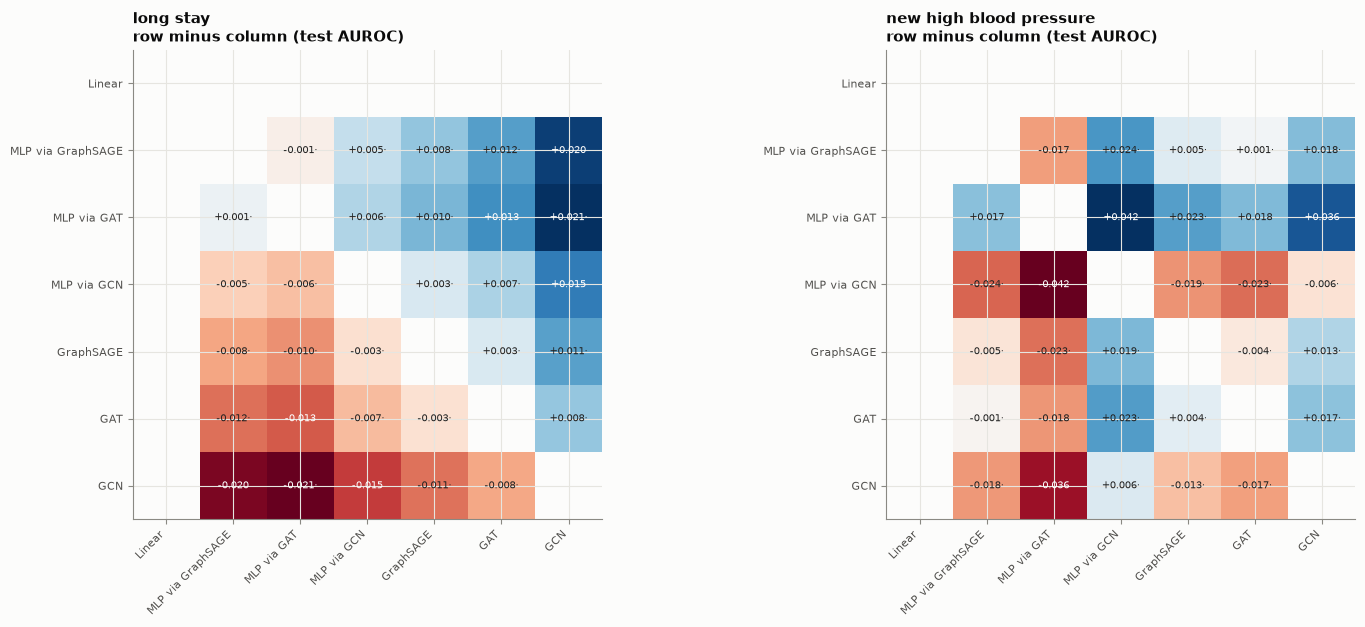

In [8]:
PW = {q: CM.pairwise(D, q) for q in TASKS.values()}
fig, axes = plt.subplots(1, len(TASKS), figsize=(15.5, 6.4))
for ax, q in zip(np.atleast_1d(axes), TASKS.values()):
    m, s = PW[q]["mean"], PW[q]["sd"]
    lim = float(np.nanmax(np.abs(m.to_numpy()))) or 0.05
    ax.imshow(m.to_numpy(), cmap="RdBu", vmin=-lim, vmax=lim)
    ax.set_xticks(range(len(m))); ax.set_xticklabels(m.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(m))); ax.set_yticklabels(m.index, fontsize=8)
    for i in range(len(m)):
        for j in range(len(m)):
            v = m.iat[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:+.3f}" + ("·" if abs(v) < s.iat[i, j] else ""), ha="center", va="center", fontsize=7.5,
                        color="white" if abs(v) > 0.6 * lim else "#222")
    ax.set_title(f"{q}\nrow minus column (test AUROC)")
plt.tight_layout()
nf.save(fig, p.figures / "17_pairwise.png")
plt.show()

## Year-adjusted view

Test AUROC **within** calendar-year bands (2015 is the coding switch), honest network and honest diagnoses, over the shared seeds. A model that wins only by learning the calendar will not keep its score here. Bands with fewer than 10 positive or 10 negative test stays are blank, so the blood-pressure bands are noisy.

In [9]:
band_cols = [c for c in (f"auc_{b}" for b in YEAR_BANDS) if c in D.columns]
for q in TASKS.values():
    labels = [l for l in CM.CORE if len(CM.get(D, q, l, *CM.HONEST))]
    seeds = CM.common_seeds(D, q, labels)
    t = pd.DataFrame({l: CM.get(D, q, l, *CM.HONEST).loc[seeds, ["test_auc", *band_cols]].mean() for l in labels}).T
    print(q); display(t.round(3))

long stay


,test_auc,auc_2007-2014,auc_2015-2018,auc_2019-2023
Linear,0.747,0.736,0.750,0.762
MLP via GraphSAGE,0.776,0.749,0.799,0.804
MLP via GAT,0.777,0.745,0.798,0.813
MLP via GCN,0.771,0.749,0.786,0.794
GraphSAGE,0.768,0.745,0.787,0.785
GAT,0.765,0.729,0.789,0.796
GCN,0.756,0.721,0.777,0.789


new high blood pressure


,test_auc,auc_2007-2014,auc_2015-2018,auc_2019-2023
Linear,0.594,0.580,0.609,0.549
MLP via GraphSAGE,0.673,0.608,0.744,0.678
MLP via GAT,0.691,0.626,0.746,0.680
MLP via GCN,0.649,0.602,0.697,0.645
GraphSAGE,0.668,0.608,0.729,0.659
GAT,0.672,0.613,0.740,0.627
GCN,0.655,0.601,0.734,0.611


In [10]:
# aggregate numbers only (no patient data)
pd.concat(LB, names=["question"]).reset_index().to_csv(p.results / "model_comparison_leaderboard.csv", index=False)
pd.concat([pd.concat(NE, names=["question"]).reset_index(level=0).assign(table="network effects"),
           pd.concat(CE, names=["question"]).reset_index(level=0).assign(table="cheating effects")]) \
  .to_csv(p.results / "model_comparison_effects.csv", index=False)

## What we learned

*(fill in after running)*

- **Who is best?** The leaderboard rank and `share_of_splits_won`. Is the best model clearly ahead of the second, or within the spread?
- **Is it the network?** For each architecture, `network − its own MLP`. If that is within its spread of zero, the gain over the linear model is the nonlinearity, not the links.
- **Do the architectures differ?** Compare the differences *between* networks with the differences *between* the three MLPs (the noise floor). A gap no larger than the MLP gap is not an architecture effect.
- **Linear vs MLP.** `MLP vs Linear` in the pairwise matrix: how much does a small nonlinear model add with no network at all?
- **Cheating.** Is the diagnosis leak the same size in every model? Does a cheating network add anything on top of it?
- **Year.** Does every model clear the year-alone reference, and does the ranking survive within the year bands?

## Read these results carefully

- **Spread is split-to-split.** The test sets of different seeds overlap, so the spread describes how much results move with the split, not independent trials. Paired differences are far more reliable than the means.
- **Unequal tuning budgets.** The linear model chose its penalty from seven values; each network chose between two settings. A difference between families includes how much each was tuned.
- **Selection on validation.** Settings and stopping epochs were chosen on the validation stays inside each run; the test stays were scored once.
- **Same-patient links and time.** About a third of links join two stays of one patient. A link to a patient's *later* stay may bring in that stay's record; the "no same-patient links" rows show how much each result depends on them.
- **Transductive.** Every network saw all stays' features and links during training (never the test outcomes).
- **Small positive counts.** Blood pressure has about 90 positive test stays, so differences of a point or two are noise.
- **CLMBR.** Runs restricted to stays with a CLMBR vector have different splits and are deliberately left out of every pairing here.